# رگرسیون — از خط ساده تا بیش‌برازش — نوت‌بوک همراه ارائهٔ دوم 📈

**درس داده‌کاوی و یادگیری ماشین** | استاد درس: دکتر محمدرضا سلطان آقایی | ارائه‌دهنده: [نام و نام‌خانوادگی شما]

همراهِ اسلایدهای ۱۶ تا ۱۸ ارائهٔ دوم. دیتاست، همان دیتاست واقعی دورهٔ IBM (edX) است: **مصرف سوخت و انتشار CO2 خودروهای سبک کانادایی (سال ۲۰۱۴)**.

**ساختار:**
۱. دادهٔ واقعی CO2 — آشنایی و تقسیم آموزش/آزمون
۲. رگرسیون خطی ساده: ŷ = θ₀ + θ₁x و کمینه‌سازی MSE
۳. رگرسیون چندگانه — با سه ویژگی
۴. رگرسیون چندجمله‌ای و نمایش زندهٔ بیش‌برازش
۵. معیارهای ارزیابی: MAE، MSE، RMSE، R²
۶. تمرین‌های پیشنهادی
---
### 🛠 راهنمای استفاده
- **ابزار:** همهٔ کدها در **Google Colab** اجرا می‌شوند — بدون نصبِ پایتون یا کتابخانه؛ فقط مرورگر و اینترنت (اجرای هر سلول: **Shift+Enter** یا منوی Runtime ▸ Run all).
- **یادگیری پایتون، از صفر:** [W3Schools — Python Tutorial](https://www.w3schools.com/python/default.asp) — آموزش تعاملی و رایگان؛ مثال‌ها را همان‌جا اجرا و ویرایش کنید.
- **هر سلول:** توضیح فارسی در بالای سلول و کامنت‌های فارسی داخل کد آمده است؛ خروجی‌ها هم از قبل ذخیره شده‌اند.


## ۱) دادهٔ واقعی CO2

ستون‌های مهم برای ما: `ENGINESIZE` (لیتر)، `CYLINDERS`، `FUELCONSUMPTION_COMB` (لیتر بر ۱۰۰ کیلومتر) و هدف: `CO2EMISSIONS` (گرم بر کیلومتر).

In [1]:
# بارگذاری دیتاست واقعی IBM (مصرف سوخت/CO2) از GitHub — همان دیتاست اسلاید
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

URL = ('https://raw.githubusercontent.com/sudhanshu456/Machine-Learning-with-Python-IBM/'
       'master/Week%202/Data_set/FuelConsumption.csv')
df = pd.read_csv(URL)          # اگر دانلود نشد، فایل را از کنار همین نوت‌بوک بخوانید
print(df.shape)
df[['ENGINESIZE', 'CYLINDERS', 'FUELCONSUMPTION_COMB', 'CO2EMISSIONS']].head()

(1067, 13)


,ENGINESIZE,CYLINDERS,FUELCONSUMPTION_COMB,CO2EMISSIONS
0,2.0,4,8.5,196
1,2.4,4,9.6,221
2,1.5,4,5.9,136
3,3.5,6,11.1,255
4,3.5,6,10.6,244


آموزش: 906 خودرو | آزمون: 161 خودرو


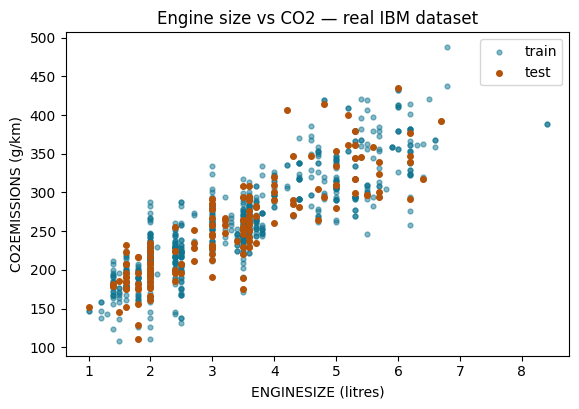

In [2]:
# تقسیم ۸۵٪/۱۵٪ و مصورسازی train/test — مدل فقط دادهٔ آموزش را می‌بیند
train, test = train_test_split(df, test_size=0.15, random_state=42)
print(f'آموزش: {len(train)} خودرو | آزمون: {len(test)} خودرو')

plt.figure(figsize=(6.5, 4.2))
plt.scatter(train.ENGINESIZE, train.CO2EMISSIONS, s=12, alpha=.5, color='#0E7490', label='train')
plt.scatter(test.ENGINESIZE, test.CO2EMISSIONS, s=16, color='#B45309', label='test')
plt.xlabel('ENGINESIZE (litres)'); plt.ylabel('CO2EMISSIONS (g/km)')
plt.title('Engine size vs CO2 — real IBM dataset'); plt.legend(); plt.show()

## ۲) رگرسیون خطی ساده — ŷ = θ₀ + θ₁x₁

خطی که **میانگین مربعات خطا (MSE)** را کمینه کند. برای هر نقطه، «خطای باقیمانده» فاصلهٔ عمودی نقطه تا خط است:
$MSE = \frac{1}{n}\sum (y_i - \hat{y}_i)^2$

θ₀ (intercept) = 125.84
θ₁ (slope)     = 39.06
معادلهٔ خط: CO2 = 125.8 + 39.1 × ENGINESIZE


/home/z/.venv/lib/python3.12/site-packages/sklearn/base.py:493: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/home/z/.venv/lib/python3.12/site-packages/sklearn/base.py:493: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/home/z/.venv/lib/python3.12/site-packages/sklearn/base.py:493: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


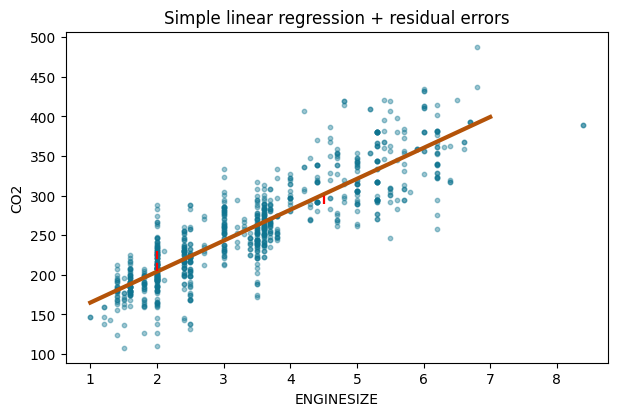

In [3]:
# رگرسیون خطی ساده: CO2 = θ₀ + θ₁×ENGINESIZE + نمایش خطاهای باقیمانده
Xtr, Xte = train[['ENGINESIZE']], test[['ENGINESIZE']]
ytr, yte = train.CO2EMISSIONS, test.CO2EMISSIONS

reg = LinearRegression().fit(Xtr, ytr)
th0, th1 = reg.intercept_, reg.coef_[0]
print(f'θ₀ (intercept) = {th0:.2f}')
print(f'θ₁ (slope)     = {th1:.2f}')
print(f'معادلهٔ خط: CO2 = {th0:.1f} + {th1:.1f} × ENGINESIZE')

gx = np.linspace(1, 7, 50)
plt.figure(figsize=(7, 4.3))
plt.scatter(Xtr.ENGINESIZE, ytr, s=10, alpha=.4, color='#0E7490')
plt.plot(gx, reg.predict(gx[:, None]), color='#B45309', lw=3)
for xv, yv in [(2.0, 230), (4.5, 290)]:
    yh = reg.predict([[xv]])[0]
    plt.plot([xv, xv], [yv, yh], 'r--', lw=1.6)
plt.xlabel('ENGINESIZE'); plt.ylabel('CO2')
plt.title('Simple linear regression + residual errors')
plt.show()

**پیدا کردن پارامترها به دو روش (طبق منبع درس):**
- **روش ریاضی (OLS — حداقل مربعات معمولی):** راه‌حل بسته با جبر خطی — همان کاری که `LinearRegression` بالا کرد؛ سریع ولی برای بیش از ~۱۰ هزار نمونه کند می‌شود.
- **بهینه‌سازی (نزول گرادیان):** شروع از مقدار تصادفی و گام‌به‌گام به‌سمت کمینه — برای همین الگوریتم‌هایی مثل `SGDRegressor` ساخته شده.

In [4]:
# نزول گرادیان دستی روی همان مسئله (برای دیدن ایدهٔ بهینه‌سازی)
w, b, lr, n = 0.0, 0.0, 1e-4, len(Xtr)
x = Xtr.ENGINESIZE.values
for i in range(60):
    yhat = w*x + b
    gw, gb = ((yhat-ytr)*x).mean(), (yhat-ytr).mean()   # گرادیان MSE
    w, b = w - lr*gw*2, b - lr*gb*2
print(f'gradient descent: w = {w:.2f} , b = {b:.2f}   (OLS: {th1:.2f} , {th0:.2f})')

gradient descent: w = 10.39 , b = 2.85   (OLS: 39.06 , 125.84)


## ۳) رگرسیون چندگانه — با سه ویژگی

حالا به‌جای فقط اندازهٔ موتور، **اندازهٔ موتور + تعداد سیلندر + مصرف سوخت ترکیبی** را می‌دهیم:

In [5]:
# رگرسیون چندگانه با ۳ ویژگی — MAE/RMSE/R² در برابر مدلِ تک‌ویژگی
cols = ['ENGINESIZE', 'CYLINDERS', 'FUELCONSUMPTION_COMB']
regm = LinearRegression().fit(train[cols], ytr)
print('ضرایب:')
for c, k in zip(cols, regm.coef_):
    print(f'  {c:24s} {k:+.2f}')
print(f'  intercept               {regm.intercept_:+.2f}')

pred_simple = reg.predict(Xte)
pred_multi = regm.predict(test[cols])
cmp = pd.DataFrame({
    'MAE':  [mean_absolute_error(yte, pred_simple), mean_absolute_error(yte, pred_multi)],
    'RMSE': [np.sqrt(mean_squared_error(yte, pred_simple)), np.sqrt(mean_squared_error(yte, pred_multi))],
    'R2':   [r2_score(yte, pred_simple), r2_score(yte, pred_multi)],
}, index=['ساده (فقط ENGINESIZE)', 'چندگانه (۳ ویژگی)'])
cmp.round(2)

ضرایب:
  ENGINESIZE               +11.28
  CYLINDERS                +7.33
  FUELCONSUMPTION_COMB     +9.39
  intercept               +67.39


,MAE,RMSE,R2
ساده (فقط ENGINESIZE),23.88,31.53,0.74
چندگانه (۳ ویژگی),16.72,22.92,0.86


همان‌طور که در اسلاید ۱۷ دیدیم: با سه ویژگی، **R² آزمون از ۰.۷۴ به ۰.۸۶** رسید.

## ۴) رگرسیون چندجمله‌ای و نمایش زندهٔ بیش‌برازش

نکتهٔ ظریف منبع درس: اگر $X^2$ دارید، آن را **متغیر جدید** در نظر بگیرید — چندجمله‌ای حالت خاصی از رگرسیون چندگانه است.
حالا یک نمایش زنده از طیف **کم‌برازش ← برازش خوب ← بیش‌برازش** روی دادهٔ موج‌دار:

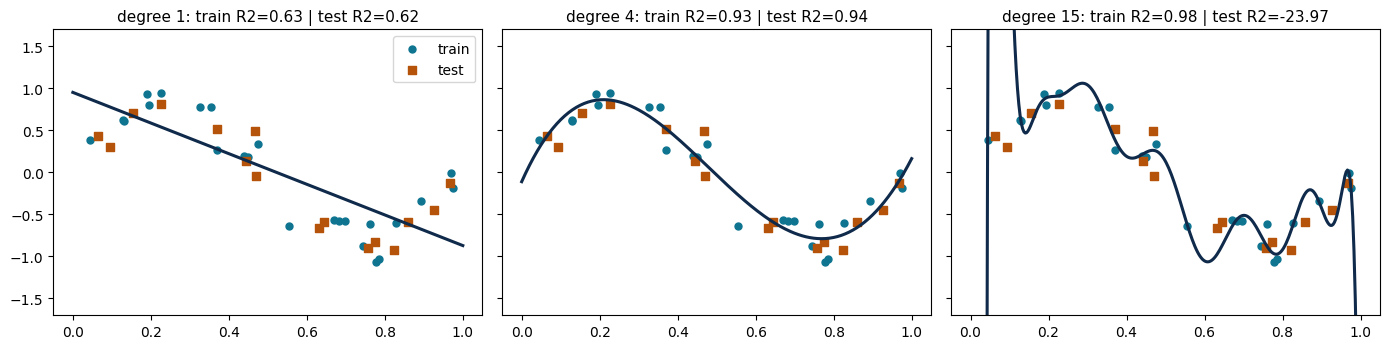

In [6]:
# بیش‌برازش چندجمله‌ای: degree=۱۵ روی train عالی است اما روی test فاجعه
rng = np.random.default_rng(42)
n = 40
xh = np.sort(rng.uniform(0, 1, n))
yh = np.sin(2*np.pi*xh)*0.8 + rng.normal(0, .22, n)
Xtr2, Xte2, ytr2, yte2 = train_test_split(xh[:, None], yh, test_size=.4, random_state=7)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
gx = np.linspace(0, 1, 300)[:, None]
for ax, d in zip(axes, [1, 4, 15]):
    pf = PolynomialFeatures(d)
    rp = LinearRegression().fit(pf.fit_transform(Xtr2), ytr2)
    r2tr = r2_score(ytr2, rp.predict(pf.transform(Xtr2)))
    r2te = r2_score(yte2, rp.predict(pf.transform(Xte2)))
    ax.scatter(Xtr2[:, 0], ytr2, s=25, color='#0E7490', label='train')
    ax.scatter(Xte2[:, 0], yte2, s=30, color='#B45309', marker='s', label='test')
    ax.plot(gx[:, 0], rp.predict(pf.transform(gx)), color='#0F2A4A', lw=2.2)
    ax.set_ylim(-1.7, 1.7)
    ax.set_title(f'degree {d}: train R2={r2tr:.2f} | test R2={r2te:.2f}', fontsize=11)
axes[0].legend()
plt.tight_layout(); plt.show()

In [7]:
# همان داستان روی خود دادهٔ CO2: درجه‌های ۱ تا ۵
rows = []
for d in range(1, 6):
    pf = PolynomialFeatures(d)
    P = pf.fit_transform(train[['ENGINESIZE']])
    rp = LinearRegression().fit(P, ytr)
    rows.append({
        'درجه': d,
        'R2 آموزش': r2_score(ytr, rp.predict(P)),
        'R2 آزمون': r2_score(yte, rp.predict(pf.transform(Xte))),
    })
pd.DataFrame(rows).round(3)

,درجه,R2 آموزش,R2 آزمون
0,1,0.769,0.736
1,2,0.771,0.741
2,3,0.772,0.742
3,4,0.772,0.740
4,5,0.773,0.740


**هر چه درجه بالاتر، R² آموزش بهتر — ولی بهبود آزمون خیلی زود پلاتو می‌شود.** روی دادهٔ موج‌دار مصنوعی، درجهٔ ۱۵ حتی R² آزمون **منفی** می‌کند (یعنی بدتر از حدس میانگین!) — بیش‌برازش کلاسیک.

## ۵) معیارهای ارزیابی رگرسیون — یک‌جا

| معیار | فرمول | خاصیت |
|---|---|---|
| MAE | میانگین \|y−ŷ\| | مقاوم به خطاهای بزرگ، همان مقیاس داده |
| MSE | میانگین (y−ŷ)² | خطاهای بزرگ را سنگین جریمه می‌کند |
| RMSE | √MSE | **همان واحد y** — قابل تفسیر |
| R² | ۱ − SSE/SST | سهم واریانس توضیح‌داده‌شده؛ بالاتر = بهتر |

In [8]:
# تابع ارزیابی مشترک: MAE، RMSE و R² برای هر مدل — همان جدول اسلاید
def evaluate(name, y_true, y_pred):
    return {'مدل': name,
            'MAE': mean_absolute_error(y_true, y_pred),
            'MSE': mean_squared_error(y_true, y_pred),
            'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
            'R2': r2_score(y_true, y_pred)}

results = pd.DataFrame([
    evaluate('خطی ساده (test)', yte, pred_simple),
    evaluate('چندگانه ۳ ویژگی (test)', yte, pred_multi),
    evaluate('خطی ساده (train)', ytr, reg.predict(Xtr)),
])
results.round(2)

,مدل,MAE,MSE,RMSE,R2
0,خطی ساده (test),23.88,994.00,31.53,0.74
1,چندگانه ۳ ویژگی (test),16.72,525.10,22.92,0.86
2,خطی ساده (train),23.27,937.97,30.63,0.77


**تفسیر RMSE به واحد واقعی:** چندگانه RMSE ≈ ۲۳ گرم بر کیلومتر — یعنی خطای معمول مدل در پیش‌بینی CO2 یک خودرو حدود ۲۳ g/km است. مقایسهٔ train و test هم ساده‌ترین آزمون بیش‌برازش است: اگر test خیلی بدتر از train باشد، مدل دادهٔ آموزش را «حفظ کرده» است.

## ۶) تمرین‌های پیشنهادی ✅

1. به‌جای `ENGINESIZE`، از `FUELCONSUMPTION_COMB` به‌عنوان تنها ویژگی استفاده کنید — کدام R² آزمون بالاتر می‌رود؟ (این دقیقاً تمرین دورهٔ IBM است!)
2. چندجمله‌ای روی `FUELCONSUMPTION_COMB` تا درجهٔ ۷ برازش کنید و نقطهٔ توقف بهبود آزمون را پیدا کنید.
3. نکتهٔ منبع درس: «برای انتخاب Xها دفاع نظری داشته باشید» — با `df.corr()` همبستگی ویژگی‌ها را ببینید و دو ویژگی بهینه انتخاب کنید.
4. (چالشی) با `SGDRegressor` همان مدل چندگانه را برازش کنید و ضرایب را با OLS مقایسه کنید.